# Liver Disease Prediction — a Clinician's Evaluation of a Simple ML Model

**Author:** Mariana Rodrigues, MD — Critical Care Physician
**Data:** Indian Liver Patient Dataset (ILPD), public dataset from the UCI Machine Learning Repository (583 patients, 9 clinical features)

**Question:** Can routine liver tests and age identify patients with liver disease — and, more importantly, *would this model be safe to use?*

**Why this matters clinically:** in a screening/triage setting, a missed case (false negative) usually costs more than a false alarm. So this notebook does not stop at accuracy: it evaluates sensitivity, threshold choice, calibration, interpretability and subgroup performance, the way a model should be judged before it gets anywhere near a patient.

> Requirements: pandas, numpy, matplotlib, seaborn, scikit-learn, openpyxl

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             brier_score_loss)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
plt.style.use("default")
sns.set_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

RANDOM_STATE = 42
DATA_FILE = "_264de4072d0e4bd88ab3c1bd1ed393f8_indian_liver_patient_dataset.xlsx"

## 1. Data

In [2]:
df = pd.read_excel(DATA_FILE)
target_col = "Outcome"          # 1 = liver disease, 0 = no liver disease
feature_cols = [c for c in df.columns if c != target_col]

print(f"Rows: {len(df):,} | Features: {len(feature_cols)}")
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0].to_string() or "  none")
print("\nClass balance:")
print(df[target_col].value_counts().rename({1: "liver disease (1)", 0: "no liver disease (0)"}).to_string())

Rows: 583 | Features: 9

Missing values per column:
Series([], )

Class balance:
Outcome
liver disease (1)       416
no liver disease (0)    167


**Clinical note:** liver disease is the *majority* class here (~71%). This is unusual for a screening population, so the prevalence, and therefore the predictive values, will not transfer to real-world settings.

## 2. Distributions — laboratory values are heavily skewed

Skewness (|skew| > 1 = strongly skewed):
Aspartate_Aminotransferase    10.55
Alamine_Aminotransferase       6.55
Total_Bilirubin                4.91
Alkaline_Phosphotase           3.77
Direct_Bilirubin               3.21
Albumin_and_Globulin_Ratio     0.98
Age                           -0.03
Albumin                       -0.04
Total_Protiens                -0.29

Will log-transform: ['Aspartate_Aminotransferase', 'Alamine_Aminotransferase', 'Total_Bilirubin', 'Alkaline_Phosphotase', 'Direct_Bilirubin']


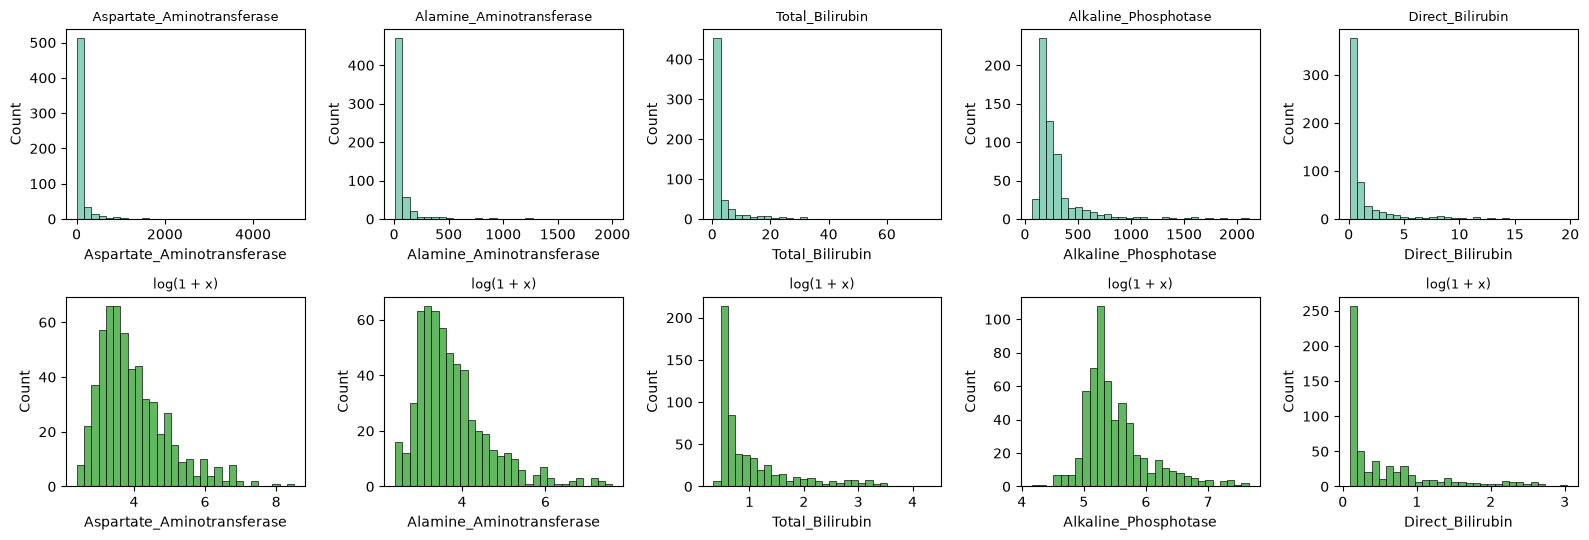

In [3]:
num_cols = df[feature_cols].select_dtypes("number").columns
skew = df[num_cols].skew().sort_values(ascending=False).round(2)
print("Skewness (|skew| > 1 = strongly skewed):")
print(skew.to_string())

SKEWED = [c for c in skew.index if skew[c] > 1]
print("\nWill log-transform:", SKEWED)

fig, axes = plt.subplots(2, len(SKEWED), figsize=(3.2 * len(SKEWED), 5.5))
for i, col in enumerate(SKEWED):
    sns.histplot(df[col], ax=axes[0, i], bins=30)
    axes[0, i].set_title(col, fontsize=9)
    sns.histplot(np.log1p(df[col]), ax=axes[1, i], bins=30, color="tab:green")
    axes[1, i].set_title("log(1 + x)", fontsize=9)
plt.tight_layout(); plt.show()

Bilirubin, alkaline phosphatase and aminotransferases span orders of magnitude (as at the bedside). A linear model on the raw values lets a few extreme results dominate; a log transform is the standard fix.

## 3. Train/test split (same stratified 80/20 split as the original analysis)

In [4]:
X, y = df[feature_cols], df[target_col]
test_idx = df.groupby(target_col, group_keys=False).sample(frac=0.2, random_state=RANDOM_STATE).index
X_test, y_test = X.loc[test_idx], y.loc[test_idx]
X_train, y_train = X.drop(test_idx), y.drop(test_idx)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (467, 9) | Test: (116, 9)


## 4. Models compared (5-fold cross-validation on the training set only)

In [5]:
OTHER = [c for c in feature_cols if c not in SKEWED]

def build(log_transform: bool, balanced: bool):
    if log_transform:
        pre = ColumnTransformer([
            ("log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p)), SKEWED),
            ("raw", SimpleImputer(strategy="median"), OTHER),
        ])
    else:
        pre = SimpleImputer(strategy="median")
    clf = LogisticRegression(class_weight="balanced" if balanced else None,
                             max_iter=1000, random_state=RANDOM_STATE)
    return make_pipeline(pre, StandardScaler(), clf)

def metrics_at(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "AUC": roc_auc_score(y_true, proba),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "PPV": tp / (tp + fp) if (tp + fp) else np.nan,
        "NPV": tn / (tn + fn) if (tn + fn) else np.nan,
        "FN (missed cases)": fn,
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "A. Original: raw values + balanced weights": build(False, True),
    "B. Raw values, no weighting":               build(False, False),
    "C. Log-transformed + balanced weights":      build(True, True),
    "D. Log-transformed, no weighting":           build(True, False),
}

rows, oof = {}, {}
for name, pipe in candidates.items():
    p = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof[name] = p
    rows[name] = metrics_at(y_train, p, 0.5)

cv_table = pd.DataFrame(rows).T.round(3)
cv_table

,AUC,Sensitivity,Specificity,PPV,NPV,FN (missed cases)
A. Original: raw values + balanced weights,0.744,0.565,0.851,0.904,0.440,145.0
"B. Raw values, no weighting",0.746,0.940,0.157,0.735,0.512,20.0
C. Log-transformed + balanced weights,0.750,0.604,0.761,0.863,0.436,132.0
"D. Log-transformed, no weighting",0.751,0.895,0.306,0.762,0.539,35.0


**Reading this table as a clinician:**
- `class_weight="balanced"` gives *more* weight to the minority class, which here is the **healthy** group. It raises specificity but sacrifices sensitivity, the opposite of what a screening tool needs.
- **AUC** measures discrimination independently of the threshold; sensitivity/specificity depend on where we put the cut-off (next step).

## 5. Choosing the decision threshold for a clinical goal

In [14]:
TARGET_SENSITIVITY = 0.90   # clinical choice: miss at most ~1 in 10 patients with liver disease

# Final model: pick the candidate with the best cross-validated AUC
best_name = cv_table["AUC"].idxmax()
print("Model with best cross-validated AUC:", best_name)

# Threshold chosen on cross-validated (out-of-fold) training predictions — never on the test set
fpr, tpr, thr = roc_curve(y_train, oof[best_name])
ok = np.where(tpr >= TARGET_SENSITIVITY)[0]
THRESHOLD = float(thr[ok[0]])
print(f"Highest threshold reaching sensitivity >= {TARGET_SENSITIVITY:.0%} in CV: {THRESHOLD:.3f}")

Model with best cross-validated AUC: D. Log-transformed, no weighting
Highest threshold reaching sensitivity >= 90% in CV: 0.495


## 6. Final evaluation on the untouched test set

In [7]:
baseline = build(False, True).fit(X_train, y_train)
final = candidates[best_name].fit(X_train, y_train)

p_base = baseline.predict_proba(X_test)[:, 1]
p_final = final.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Original model (thr 0.50)": metrics_at(y_test, p_base, 0.5),
    f"Final model (thr {THRESHOLD:.2f})": metrics_at(y_test, p_final, THRESHOLD),
}).T.round(3)
results

,AUC,Sensitivity,Specificity,PPV,NPV,FN (missed cases)
Original model (thr 0.50),0.766,0.530,0.909,0.936,0.435,39.0
Final model (thr 0.49),0.740,0.904,0.182,0.735,0.429,8.0


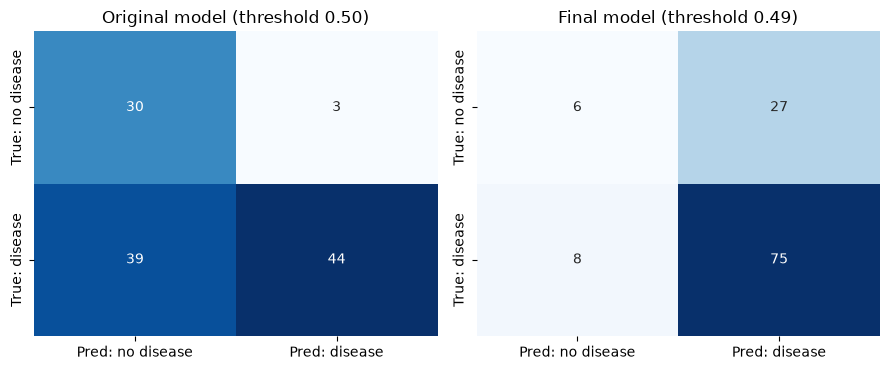

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (title, p, t) in zip(axes, [("Original model", p_base, 0.5),
                                     ("Final model", p_final, THRESHOLD)]):
    cm = confusion_matrix(y_test, (p >= t).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax,
                xticklabels=["Pred: no disease", "Pred: disease"],
                yticklabels=["True: no disease", "True: disease"])
    ax.set_title(f"{title} (threshold {t:.2f})")
plt.tight_layout(); plt.show()

## 7. ROC curve and operating points

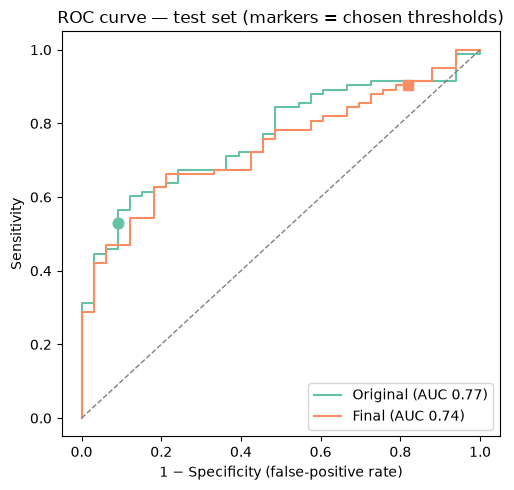

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 5))
for label, p, t, m in [("Original", p_base, 0.5, "o"), ("Final", p_final, THRESHOLD, "s")]:
    f, s, _ = roc_curve(y_test, p)
    ax.plot(f, s, label=f"{label} (AUC {roc_auc_score(y_test, p):.2f})")
    met = metrics_at(y_test, p, t)
    ax.scatter(1 - met["Specificity"], met["Sensitivity"], marker=m, s=60, zorder=3)
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
ax.set_xlabel("1 − Specificity (false-positive rate)")
ax.set_ylabel("Sensitivity")
ax.set_title("ROC curve — test set (markers = chosen thresholds)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 8. Calibration — can the predicted probabilities be trusted?

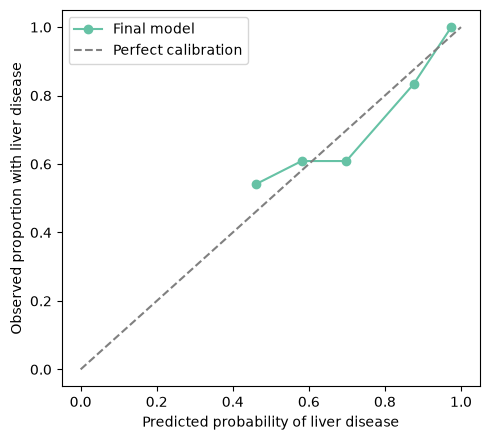

Brier score (lower is better): 0.174


In [10]:
frac_pos, mean_pred = calibration_curve(y_test, p_final, n_bins=5, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot(mean_pred, frac_pos, "o-", label="Final model")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
ax.set_xlabel("Predicted probability of liver disease")
ax.set_ylabel("Observed proportion with liver disease")
ax.legend(); plt.tight_layout(); plt.show()
print("Brier score (lower is better):", round(brier_score_loss(y_test, p_final), 3))

## 9. What drives the predictions? (odds ratio per 1 SD increase)

,Feature,Odds ratio per 1 SD,Scale
4,Direct_Bilirubin,1.87,log
6,Total_Protiens,1.86,raw
1,Alamine_Aminotransferase,1.73,log
3,Alkaline_Phosphotase,1.32,log
0,Aspartate_Aminotransferase,1.27,log
8,Albumin_and_Globulin_Ratio,1.26,raw
5,Age,1.22,raw
2,Total_Bilirubin,1.08,log
7,Albumin,0.47,raw


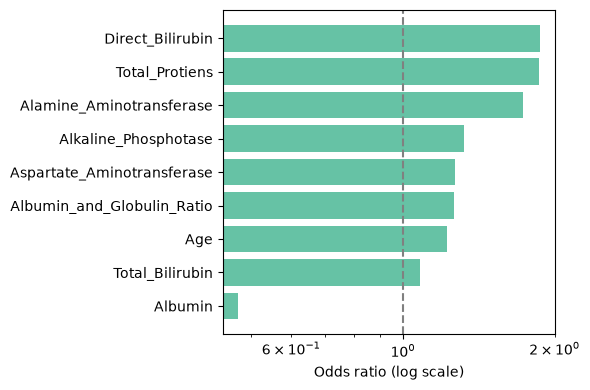

In [11]:
coefs = final[-1].coef_[0]
names = SKEWED + OTHER if "log" in str(best_name).lower() else feature_cols
or_table = (pd.DataFrame({"Feature": names, "Odds ratio per 1 SD": np.exp(coefs)})
            .assign(Scale=lambda d: ["log" if (n in SKEWED and "log" in best_name.lower()) else "raw" for n in d.Feature])
            .sort_values("Odds ratio per 1 SD", ascending=False).round(2))
display(or_table)

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(or_table["Feature"], or_table["Odds ratio per 1 SD"])
ax.axvline(1, color="grey", ls="--")
ax.set_xscale("log"); ax.set_xlabel("Odds ratio (log scale)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

**Clinical sanity check:** ALT and direct bilirubin are among the strongest predictors, which is broadly plausible for hepatobiliary disease. Two findings, however, should not be read as biology. First, total protein appears to increase risk, and total bilirubin carries almost no weight once direct bilirubin is in the model. Total protein, albumin and the A/G ratio are mathematically linked, as are total and direct bilirubin, so the model splits their effects arbitrarily (collinearity). Second, because the outcome (“liver patient”) is loosely defined, no single feature can be interpreted as a disease predictor without the clinical, social and environmental context of each patient. Individual odds ratios should therefore not be read as causal effects.

## 10. Subgroup performance — does the model work equally well for everyone?

In [12]:
# Cross-validated predictions on the full dataset give larger subgroups than the 116-patient test set
cv_all = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
p_all = cross_val_predict(candidates[best_name], X, y, cv=cv_all, method="predict_proba")[:, 1]
groups = {"Age band": pd.cut(df["Age"], [0, 40, 60, 120], labels=["<40", "40–60", ">60"])}
if "Gender" in df.columns:
    groups["Gender"] = df["Gender"]

for gname, g in groups.items():
    out = {}
    for level in g.dropna().unique():
        m = (g == level).values
        if y[m].nunique() == 2:
            out[level] = {"n": int(m.sum()), **metrics_at(y[m], p_all[m], THRESHOLD)}
    print(f"\n=== {gname} ===")
    display(pd.DataFrame(out).T.round(3))

if "Gender" not in df.columns:
    print("Note: this version of the dataset has no sex/gender column, so sex-based bias cannot be assessed.")


=== Age band ===


,n,AUC,Sensitivity,Specificity,PPV,NPV,FN (missed cases)
>60,99.0,0.752,1.000,0.074,0.742,1.000,0.0
40–60,242.0,0.770,0.935,0.125,0.780,0.368,12.0
<40,242.0,0.725,0.823,0.476,0.747,0.588,28.0


Note: this version of the dataset has no sex/gender column, so sex-based bias cannot be assessed.


## 11. Clinical interpretation 

- The original model had a sensitivity of 53%: out of 100 patients with liver disease, about 47 would be missed, with a risk of delayed care and adverse outcomes. The final model reaches 90% sensitivity, so about 10 in 100 would be missed (8 of 83 in the test set).
- This gain did not come from moving the threshold (0.49 is almost the default 0.50) but from removing class weighting, which in this dataset favoured the healthy minority. The price is specificity: it fell from 91% to 18%, so about 82 of every 100 people without liver disease would be flagged. That means extra tests (repeat labs, ultrasound), patient anxiety and higher costs. The model is only marginally better than labelling every patient as diseased, and its discrimination is modest (AUC 0.74–0.77).
- The weight of ALT makes pathophysiological sense, as it is relatively specific for hepatocellular injury. Direct (conjugated) bilirubin reflects cholestasis, whether intrahepatic or due to extrahepatic biliary obstruction. Its weight is plausible if “liver patient” includes hepatobiliary disease, but it is not specific for hepatocellular injury, which is another reason a clear outcome definition matters.
- Performance is not uniform across age groups: in patients over 60 the model flags almost everyone (specificity 7%), while in patients under 40 it misses more cases (sensitivity 82%, 28 missed). A tool like this could under-detect disease in younger patients and over-investigate older ones.

## 12. Limitations

- **Single source, old data:** one regional dataset from India; no external validation. Performance will likely drop in other populations and care settings.
- **Unrealistic prevalence:** ~71% have disease, far higher than any screening population, so PPV/NPV here do not transfer.
- **Vague outcome:** "liver patient" is not defined by a reference standard (biopsy, imaging, specific diagnosis). The model may be learning referral patterns rather than disease.
- **Small sample:** 583 patients and a 116-patient test set, so metrics have wide uncertainty and subgroup results are exploratory.
- **Missing context:** no history (alcohol, viral serology, medications), imaging or clinical signs, which are information a clinician would always use.
- **No sex variable** in this version, so a key fairness dimension cannot be checked.

## 13. Would I deploy this model? — Model card summary

| Item | Summary |
|---|---|
| Intended use | Educational exercise; **not** for clinical decision-making |
| Model | Logistic regression (log-transformed labs, standardized) |
| Operating point | Threshold tuned for ≥90% sensitivity (cross-validated) |
| Key metrics (test) | See section 6 |
| Main risks | Missed diagnoses, poor generalization, collinearity, unknown calibration in new populations |
| Verdict | *Not ready for deployment; would require external validation, a defined outcome and prospective evaluation.* |